<a href="https://colab.research.google.com/github/structuralvishnu-bit/Dr.-VP/blob/main/WPCB_ML_Google_Colab_Step_by_Step.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WPCB Concrete — Reproducible ML Analysis (Beginner Colab Notebook)

**Research purpose:** Exploratory prediction of RCPT, sorptivity, volume of permeable voids, and water absorption, using the existing *provisional* WPCB dataset.

**Scientific limits:** 117 measurements but **only 9 independent concrete mixtures**. Values are not fully reconciled against the thesis; no raw replicate readings or SD. Control (0% PCB, 0% SF) versus treated mixtures (PCB > 0, 12% SF) means effects of PCB and SF cannot be separated. This notebook does **not** claim external validation, causal interpretation, or an experimentally validated optimum.

**How to use:** In Colab, choose **Runtime → Run all**, then upload `WPCB_Provisional_ML_Filtered.csv` when asked. If a cell errors, stop and share the full error message. Run time varies; nested validation may take several minutes.

## Step 1 — Install libraries (run once per Colab session)

In [ ]:
%pip -q install xgboost catboost shap openpyxl

## Step 2 — Upload the provided provisional dataset

In [4]:

import pandas as pd
from google.colab import files
from sklearn.model_selection import LeaveOneGroupOut

uploaded = files.upload()

filename = next(iter(uploaded))
raw = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows:", len(raw))
print("Mixtures:", raw["CV_group"].nunique())

display(raw.head())


Saving WPCB_Provisional_ML_Filtered.csv to WPCB_Provisional_ML_Filtered.csv
Dataset loaded successfully!
Rows: 117
Mixtures: 9


,Grade,M65_indicator,PCB_pct,SF_pct,Age_days,CV_group,Target_property,Target_value,Reported_unit,PPT_slide,Eligibility,Limitations
0,M65,1,0,0,28,M65_PCB0_SF0,RCPT,1199.8,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
1,M65,1,5,12,28,M65_PCB5_SF12,RCPT,1115.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
2,M65,1,10,12,28,M65_PCB10_SF12,RCPT,978.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
3,M65,1,15,12,28,M65_PCB15_SF12,RCPT,995.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
4,M65,1,0,0,56,M65_PCB0_SF0,RCPT,992.6,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...


In [5]:

# =====================================================
# STEP 3: WPCB DATA INTEGRITY AND QUALITY CHECKS
# =====================================================

import pandas as pd
import numpy as np

# 1. Check whether the dataset is loaded
if "raw" not in globals():
    raise RuntimeError(
        "Dataset not loaded. Please run Step 2 first."
    )

df = raw.copy()

print("=" * 55)
print("WPCB MACHINE LEARNING - DATA INTEGRITY CHECK")
print("=" * 55)

# 2. Dataset dimensions
print("\n1. DATASET INFORMATION")
print("Total observations:", len(df))
print("Total columns:", df.shape[1])

# 3. Check independent mixtures
if "CV_group" not in df.columns:
    raise ValueError("CV_group column is missing!")

print("Independent mixtures:", df["CV_group"].nunique())

# 4. Check missing values
print("\n2. MISSING VALUES")
print(df.isnull().sum().to_string())

# 5. Check duplicate rows
print("\n3. DUPLICATE RECORDS")
print("Exact duplicate rows:", df.duplicated().sum())

# 6. Check numerical variables
print("\n4. NUMERICAL DATA SUMMARY")
display(df.describe(include="number").T)

# 7. Check data types
print("\n5. COLUMN DATA TYPES")
print(df.dtypes.to_string())

# 8. Check target distribution
print("\n6. DURABILITY TARGET DISTRIBUTION")

possible_target_columns = [
    "Property", "property", "Target",
    "target", "Durability_Property"
]

target_col = next(
    (c for c in possible_target_columns if c in df.columns),
    None
)

if target_col:
    print(df[target_col].value_counts(dropna=False))
else:
    print("No standard target column detected.")
    print("Available columns:", list(df.columns))

# 9. Check group sizes
print("\n7. OBSERVATIONS PER MIXTURE")
print(df.groupby("CV_group").size())

# 10. Final status
print("\n" + "=" * 55)
print("DATA INTEGRITY CHECK COMPLETED")
print("=" * 55)

if len(df) == 117 and df["CV_group"].nunique() == 9:
    print("Expected dataset structure confirmed.")
else:
    print("WARNING: Dataset structure differs from expected.")
    print("Review the dataset before model training.")

print("\nNext: Run STEP 4 - ML Library Imports.")


WPCB MACHINE LEARNING - DATA INTEGRITY CHECK

1. DATASET INFORMATION
Total observations: 117
Total columns: 12
Independent mixtures: 9

2. MISSING VALUES
Grade              0
M65_indicator      0
PCB_pct            0
SF_pct             0
Age_days           0
CV_group           0
Target_property    0
Target_value       0
Reported_unit      0
PPT_slide          0
Eligibility        0
Limitations        0

3. DUPLICATE RECORDS
Exact duplicate rows: 0

4. NUMERICAL DATA SUMMARY


,count,mean,std,min,25%,50%,75%,max
M65_indicator,117.0,0.444444,0.499041,0.000,0.00,0.0,1.0,1.0
PCB_pct,117.0,8.888889,6.601695,0.000,5.00,10.0,15.0,20.0
SF_pct,117.0,9.333333,5.010334,0.000,12.00,12.0,12.0,12.0
Age_days,117.0,67.384615,40.795927,28.000,28.00,56.0,90.0,180.0
Target_value,117.0,397.440786,651.863261,0.028,2.22,3.8,810.3,2189.0
PPT_slide,117.0,99.615385,7.804559,89.000,89.00,99.0,106.0,108.0



5. COLUMN DATA TYPES
Grade               object
M65_indicator        int64
PCB_pct              int64
SF_pct               int64
Age_days             int64
CV_group            object
Target_property     object
Target_value       float64
Reported_unit       object
PPT_slide            int64
Eligibility         object
Limitations         object

6. DURABILITY TARGET DISTRIBUTION
No standard target column detected.
Available columns: ['Grade', 'M65_indicator', 'PCB_pct', 'SF_pct', 'Age_days', 'CV_group', 'Target_property', 'Target_value', 'Reported_unit', 'PPT_slide', 'Eligibility', 'Limitations']

7. OBSERVATIONS PER MIXTURE
CV_group
M30_PCB0_SF0      13
M30_PCB10_SF12    13
M30_PCB15_SF12    13
M30_PCB20_SF12    13
M30_PCB5_SF12     13
M65_PCB0_SF0      13
M65_PCB10_SF12    13
M65_PCB15_SF12    13
M65_PCB5_SF12     13
dtype: int64

DATA INTEGRITY CHECK COMPLETED
Expected dataset structure confirmed.

Next: Run STEP 4 - ML Library Imports.


In [6]:

# =====================================================
# STEP 4: ML LIBRARIES AND CROSS-VALIDATION SETUP
# WPCB CONCRETE DURABILITY PREDICTION
# =====================================================

# Install additional ML libraries
%pip -q install xgboost catboost shap

# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# Data preprocessing
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Cross-validation
from sklearn.model_selection import (
    LeaveOneGroupOut,
    GroupKFold,
    GridSearchCV,
    RandomizedSearchCV
)

# Regression models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF,
    Matern,
    ConstantKernel,
    WhiteKernel
)

# Advanced ML models
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Performance metrics
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Explainable AI
import shap

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Leave-one-mixture-out cross-validation
logo = LeaveOneGroupOut()

# Confirm dataset is available
if "raw" not in globals():
    raise RuntimeError(
        "Dataset not loaded. Run Step 2 first."
    )

if "CV_group" not in raw.columns:
    raise ValueError(
        "CV_group column is missing from the dataset."
    )

groups = raw["CV_group"]

print("=" * 55)
print("WPCB ML ENVIRONMENT INITIALIZED")
print("=" * 55)

print("Dataset observations:", len(raw))
print("Independent mixtures:", groups.nunique())
print("Cross-validation:", "Leave-One-Group-Out")
print("Number of outer folds:", logo.get_n_splits(
    groups=groups
))

print("\nModels available:")
print("1. Dummy Mean Regressor")
print("2. Ridge Regression")
print("3. Random Forest Regression")
print("4. XGBoost Regression")
print("5. CatBoost Regression")
print("6. Gaussian Process Regression")

print("\nSHAP library loaded successfully.")
print("\nSTEP 4 COMPLETED SUCCESSFULLY!")
print("Next: STEP 5 - Model Training and Validation")


WPCB ML ENVIRONMENT INITIALIZED
Dataset observations: 117
Independent mixtures: 9
Cross-validation: Leave-One-Group-Out
Number of outer folds: 9

Models available:
1. Dummy Mean Regressor
2. Ridge Regression
3. Random Forest Regression
4. XGBoost Regression
5. CatBoost Regression
6. Gaussian Process Regression

SHAP library loaded successfully.

STEP 4 COMPLETED SUCCESSFULLY!
Next: STEP 5 - Model Training and Validation


Available columns:
['Grade', 'M65_indicator', 'PCB_pct', 'SF_pct', 'Age_days', 'CV_group', 'Target_property', 'Target_value', 'Reported_unit', 'PPT_slide', 'Eligibility', 'Limitations']

First five records:


,Grade,M65_indicator,PCB_pct,SF_pct,Age_days,CV_group,Target_property,Target_value,Reported_unit,PPT_slide,Eligibility,Limitations
0,M65,1,0,0,28,M65_PCB0_SF0,RCPT,1199.8,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
1,M65,1,5,12,28,M65_PCB5_SF12,RCPT,1115.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
2,M65,1,10,12,28,M65_PCB10_SF12,RCPT,978.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
3,M65,1,15,12,28,M65_PCB15_SF12,RCPT,995.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
4,M65,1,0,0,56,M65_PCB0_SF0,RCPT,992.6,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...


grade: Grade
wpcb: PCB_pct
silica_fume: SF_pct
age: Age_days

Input variables: ['Grade', 'PCB_pct', 'SF_pct', 'Age_days']

Durability properties: ['RCPT' 'Sorptivity' 'Volume of permeable voids' 'Water absorption']

TRAINING MODELS FOR: RCPT
Observations: 36
Mixture groups: 9
Dummy           | R2= -0.247 | RMSE=  533.6074 | MAE=  449.7696
Ridge           | R2=  0.621 | RMSE=  293.9865 | MAE=  253.0278
Random Forest   | R2=  0.726 | RMSE=  249.9279 | MAE=  195.1322
XGBoost         | R2=  0.810 | RMSE=  208.4904 | MAE=  130.2241
CatBoost        | R2=  0.821 | RMSE=  202.3893 | MAE=  153.9079
GPR             | R2=  0.756 | RMSE=  236.2145 | MAE=  170.9678

TRAINING MODELS FOR: Sorptivity
Observations: 27
Mixture groups: 9
Dummy           | R2= -0.240 | RMSE=    0.0201 | MAE=    0.0170
Ridge           | R2=  0.960 | RMSE=    0.0036 | MAE=    0.0029
Random Forest   | R2=  0.749 | RMSE=    0.0091 | MAE=    0.0078
XGBoost         | R2=  0.907 | RMSE=    0.0055 | MAE=    0.0051
CatBoost       

,Property,Model,Observations,Mixture_Groups,R2,RMSE,MAE
4,RCPT,CatBoost,36,9,0.820604,202.389277,153.907858
3,RCPT,XGBoost,36,9,0.809625,208.490399,130.224056
5,RCPT,GPR,36,9,0.755628,236.214511,170.967796
2,RCPT,Random Forest,36,9,0.726431,249.927874,195.132158
1,RCPT,Ridge,36,9,0.621477,293.986494,253.027780
0,RCPT,Dummy,36,9,-0.247043,533.607375,449.769618
11,Sorptivity,GPR,27,9,0.987074,0.002053,0.001561
7,Sorptivity,Ridge,27,9,0.959960,0.003613,0.002928
9,Sorptivity,XGBoost,27,9,0.906562,0.005520,0.005085
10,Sorptivity,CatBoost,27,9,0.888342,0.006034,0.005459



BEST MODEL FOR EACH PROPERTY


,Property,Model,Observations,Mixture_Groups,R2,RMSE,MAE
11,Sorptivity,GPR,27,9,0.987074,0.002053,0.001561
23,Water absorption,GPR,27,9,0.938366,0.203084,0.157093
17,Volume of permeable voids,GPR,27,9,0.907711,0.368407,0.285281
4,RCPT,CatBoost,36,9,0.820604,202.389277,153.907858


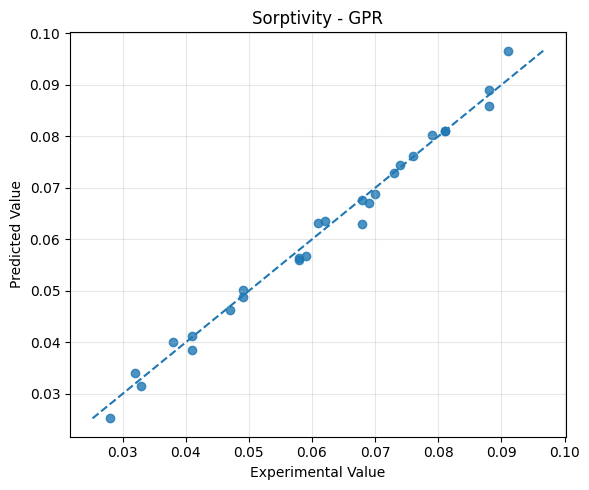

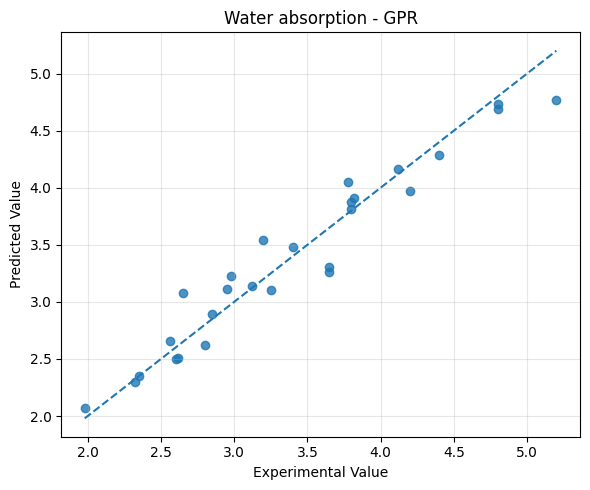

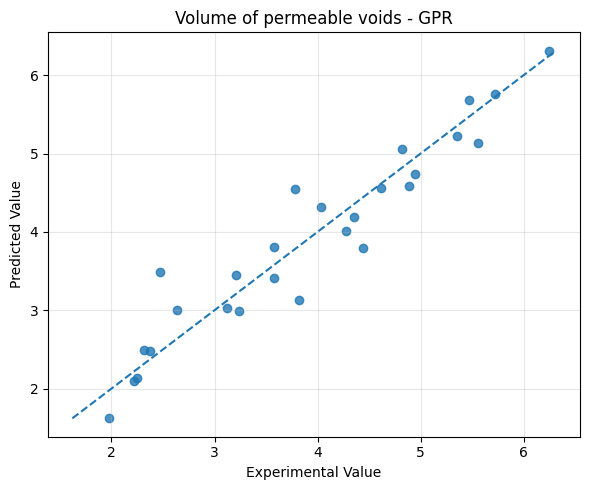

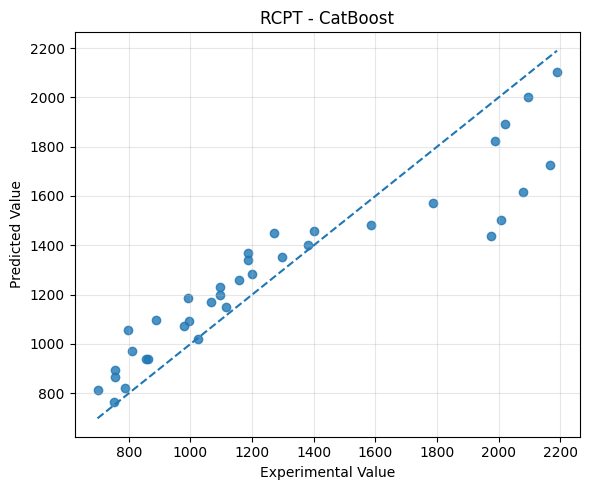


STEP 5 COMPLETED SUCCESSFULLY!
Results and prediction figures have been saved.


In [8]:
# ============================================================
# STEP 5: WPCB ML MODEL TRAINING AND GROUPED VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# ------------------------------------------------------------
# 1. CHECK DATASET
# ------------------------------------------------------------

if "raw" not in globals():
    raise RuntimeError("Run Step 2 to load the CSV first.")

df = raw.copy()

print("Available columns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

# ------------------------------------------------------------
# 2. IDENTIFY DATA COLUMNS
# ------------------------------------------------------------

def find_column(candidates, columns):
    lookup = {str(c).lower(): c for c in columns}
    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

group_col = find_column(["CV_group"], df.columns)

target_col = find_column(
    ["Target_property", "Property", "property", "Target", "target",
     "Durability_Property", "property_name"],
    df.columns
)

value_col = find_column(
    ["Target_value", "Value", "value", "Measured_Value", "measured_value",
     "Result", "result", "target_value"],
    df.columns
)

if group_col is None:
    raise ValueError("CV_group column is missing.")

if target_col is None or value_col is None:
    raise ValueError(
        "Could not identify property and value columns. "
        "Check the column names printed above. "
        "Do not substitute unrelated columns."
    )

# ------------------------------------------------------------
# 3. DEFINE INPUT VARIABLES
# ------------------------------------------------------------

# Only measured/design variables should be predictors.
# Do not use source identifiers or target values.

feature_candidates = {
    "grade": [
        "Grade", "grade", "Concrete_Grade", "grade_mpa"
    ],
    "wpcb": [
        "WPCB_pct", "wpcb_pct", "PCB_pct",
        "pcb_pct", "WPCB_percentage"
    ],
    "silica_fume": [
        "SF_pct", "sf_pct", "Silica_Fume_pct",
        "silica_fume_pct"
    ],
    "age": [
        "Age_days", "age_days", "Age",
        "age", "Testing_Age"
    ]
}

feature_cols = []

for label, candidates in feature_candidates.items():
    match = find_column(candidates, df.columns)
    if match is not None:
        feature_cols.append(match)
        print(f"{label}: {match}")

if len(feature_cols) < 3:
    raise ValueError(
        "Fewer than three expected input variables found. "
        "Please share the printed column names so the "
        "correct features can be mapped."
    )

print("\nInput variables:", feature_cols)

# ------------------------------------------------------------
# 4. CLEAN DATA WITHOUT INVENTING VALUES
# ------------------------------------------------------------

df[value_col] = pd.to_numeric(
    df[value_col], errors="coerce"
)

# Convert grade labels such as M30 and M65 to 30 and 65.
for col in feature_cols:
    if "grade" in col.lower():
        df[col] = (
            df[col].astype(str)
            .str.upper()
            .str.replace("M", "", regex=False)
        )

    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[target_col, value_col, group_col]
).copy()

# Missing predictor values will be imputed within each
# training fold, not using the entire dataset.

# ------------------------------------------------------------
# 5. DEFINE SIX ML MODELS
# ------------------------------------------------------------

def create_models():

    return {
        "Dummy": DummyRegressor(strategy="mean"),

        "Ridge": Ridge(alpha=1.0),

        "Random Forest": RandomForestRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=150,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=2
        ),

        "CatBoost": CatBoostRegressor(
            iterations=150,
            depth=2,
            learning_rate=0.05,
            loss_function="RMSE",
            random_seed=42,
            verbose=False,
            thread_count=2
        ),

        "GPR": GaussianProcessRegressor(
            kernel=(
                1.0 * Matern(nu=1.5)
                + WhiteKernel(noise_level=0.1)
            ),
            alpha=1e-6,
            normalize_y=True,
            random_state=42,
            n_restarts_optimizer=0
        )
    }

# ------------------------------------------------------------
# 6. LEAVE-ONE-MIXTURE-OUT CROSS-VALIDATION
# ------------------------------------------------------------

logo = LeaveOneGroupOut()

all_results = []
all_predictions = []

properties = df[target_col].dropna().unique()

print("\nDurability properties:", properties)

for prop in properties:

    subset = df[df[target_col] == prop].copy()

    X = subset[feature_cols].copy()
    y = subset[value_col].to_numpy(dtype=float)
    groups = subset[group_col].to_numpy()

    if len(np.unique(groups)) < 4:
        print(f"Skipping {prop}: insufficient mixture groups")
        continue

    print("\n" + "=" * 60)
    print("TRAINING MODELS FOR:", prop)
    print("Observations:", len(subset))
    print("Mixture groups:", len(np.unique(groups)))
    print("=" * 60)

    for model_name, model in create_models().items():

        predictions = np.full(len(subset), np.nan)

        for train_idx, test_idx in logo.split(
            X, y, groups=groups
        ):

            steps = [
                ("imputer", SimpleImputer(
                    strategy="median",
                    keep_empty_features=True
                ))
            ]

            # Scaling is important for Ridge and GPR.
            if model_name in ["Ridge", "GPR"]:
                steps.append(("scaler", StandardScaler()))

            steps.append(("model", model))

            pipeline = Pipeline(steps)

            pipeline.fit(
                X.iloc[train_idx],
                y[train_idx]
            )

            predictions[test_idx] = pipeline.predict(
                X.iloc[test_idx]
            )

        # Pooled out-of-fold metrics.
        r2 = r2_score(y, predictions)

        mae = mean_absolute_error(y, predictions)

        rmse = np.sqrt(
            mean_squared_error(y, predictions)
        )

        all_results.append({
            "Property": prop,
            "Model": model_name,
            "Observations": len(y),
            "Mixture_Groups": len(np.unique(groups)),
            "R2": r2,
            "RMSE": rmse,
            "MAE": mae
        })

        for i in range(len(y)):
            all_predictions.append({
                "Property": prop,
                "Model": model_name,
                "CV_group": groups[i],
                "Observed": y[i],
                "Predicted": predictions[i],
                "Residual": y[i] - predictions[i]
            })

        print(
            f"{model_name:15s} | "
            f"R2={r2:7.3f} | "
            f"RMSE={rmse:10.4f} | "
            f"MAE={mae:10.4f}"
        )

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)
predictions_df = pd.DataFrame(all_predictions)

if results_df.empty:
    raise RuntimeError(
        "No models were evaluated. Check property names, "
        "feature columns and mixture groups."
    )

results_df = results_df.sort_values(
    ["Property", "R2"],
    ascending=[True, False]
)

results_df.to_csv(
    "WPCB_ML_Model_Comparison.csv",
    index=False
)

predictions_df.to_csv(
    "WPCB_ML_Predictions.csv",
    index=False
)

print("\nMODEL COMPARISON")
display(results_df)

# ------------------------------------------------------------
# 8. IDENTIFY BEST MODEL PER PROPERTY
# ------------------------------------------------------------

best_models = (
    results_df.sort_values("R2", ascending=False)
    .drop_duplicates("Property")
)

print("\nBEST MODEL FOR EACH PROPERTY")
display(best_models)

best_models.to_csv(
    "WPCB_Best_Models.csv",
    index=False
)

# ------------------------------------------------------------
# 9. GENERATE OBSERVED VS PREDICTED FIGURES
# ------------------------------------------------------------

for _, row in best_models.iterrows():

    prop = row["Property"]
    model_name = row["Model"]

    plot_df = predictions_df[
        (predictions_df["Property"] == prop)
        & (predictions_df["Model"] == model_name)
    ]

    plt.figure(figsize=(6, 5))

    plt.scatter(
        plot_df["Observed"],
        plot_df["Predicted"],
        alpha=0.8
    )

    low = min(
        plot_df["Observed"].min(),
        plot_df["Predicted"].min()
    )

    high = max(
        plot_df["Observed"].max(),
        plot_df["Predicted"].max()
    )

    plt.plot(
        [low, high],
        [low, high],
        linestyle="--"
    )

    plt.xlabel("Experimental Value")
    plt.ylabel("Predicted Value")
    plt.title(f"{prop} - {model_name}")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    filename = (
        "WPCB_" +
        str(prop).replace(" ", "_").replace("/", "_") +
        "_Prediction.png"
    )

    plt.savefig(filename, dpi=300)
    plt.show()

print("\nSTEP 5 COMPLETED SUCCESSFULLY!")
print("Results and prediction figures have been saved.")

In [9]:

# STEP 5A: Download all ML results

from google.colab import files
import zipfile
import os

output_files = [
    "WPCB_ML_Model_Comparison.csv",
    "WPCB_ML_Predictions.csv",
    "WPCB_Best_Models.csv"
]

# Include generated prediction figures
output_files += [
    f for f in os.listdir()
    if f.startswith("WPCB_") and f.endswith(".png")
]

with zipfile.ZipFile("WPCB_Step5_Results.zip", "w") as z:
    for filename in output_files:
        if os.path.exists(filename):
            z.write(filename)

print("Results ZIP created successfully!")
files.download("WPCB_Step5_Results.zip")


Results ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset rows: 117
Independent mixtures: 9
Targets: ['RCPT' 'Sorptivity' 'Volume of permeable voids' 'Water absorption']

TARGET: RCPT
Records: 36
Groups: 9
Fold 1/9 | M30_PCB0_SF0 | GPR | MAE=692.37519
Fold 2/9 | M30_PCB10_SF12 | Ridge | MAE=202.88793
Fold 3/9 | M30_PCB15_SF12 | Ridge | MAE=220.25964
Fold 4/9 | M30_PCB20_SF12 | GPR | MAE=91.60910
Fold 5/9 | M30_PCB5_SF12 | Ridge | MAE=381.97065
Fold 6/9 | M65_PCB0_SF0 | CatBoost | MAE=203.68244
Fold 7/9 | M65_PCB10_SF12 | XGBoost | MAE=68.59692
Fold 8/9 | M65_PCB15_SF12 | XGBoost | MAE=67.51976
Fold 9/9 | M65_PCB5_SF12 | XGBoost | MAE=64.16346

TARGET: Sorptivity
Records: 27
Groups: 9
Fold 1/9 | M30_PCB0_SF0 | Ridge | MAE=0.00593
Fold 2/9 | M30_PCB10_SF12 | Ridge | MAE=0.00168
Fold 3/9 | M30_PCB15_SF12 | Ridge | MAE=0.00106
Fold 4/9 | M30_PCB20_SF12 | Ridge | MAE=0.00250
Fold 5/9 | M30_PCB5_SF12 | Ridge | MAE=0.00215
Fold 6/9 | M65_PCB0_SF0 | Ridge | MAE=0.00596
Fold 7/9 | M65_PCB10_SF12 | Ridge | MAE=0.00311
Fold 8/9 | M65_PCB15_SF12 

,Property,Observations,Independent_mixtures,Nested_R2,Nested_RMSE,Nested_MAE
0,RCPT,36,9,0.599958,302.227506,221.451676
1,Sorptivity,27,9,0.958534,0.003677,0.002889
2,Volume of permeable voids,27,9,0.846215,0.475566,0.390137
3,Water absorption,27,9,0.944575,0.192584,0.157994



MIXTURE-LEVEL ROBUSTNESS


,Property,CV_group,N,MAE,Mean_Residual
0,RCPT,M30_PCB0_SF0,4,692.375186,692.375186
1,RCPT,M30_PCB10_SF12,4,202.887928,-202.887928
2,RCPT,M30_PCB15_SF12,4,220.259640,-220.259640
3,RCPT,M30_PCB20_SF12,4,91.609098,-82.521727
4,RCPT,M30_PCB5_SF12,4,381.970646,381.970646
5,RCPT,M65_PCB0_SF0,4,203.682444,-203.682444
6,RCPT,M65_PCB10_SF12,4,68.596918,-42.338910
7,RCPT,M65_PCB15_SF12,4,67.519763,-67.519763
8,RCPT,M65_PCB5_SF12,4,64.163464,35.213776
9,Sorptivity,M30_PCB0_SF0,3,0.005932,-0.005932


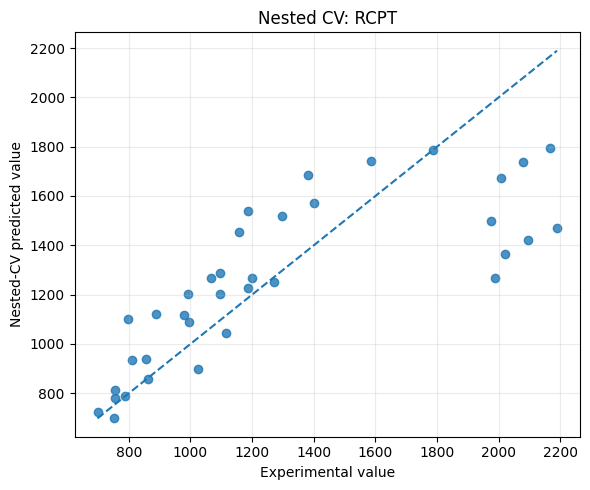

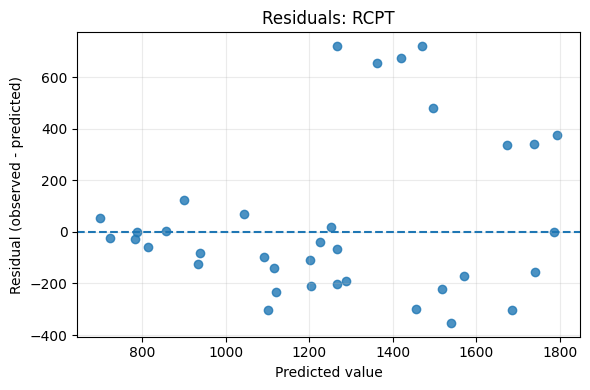

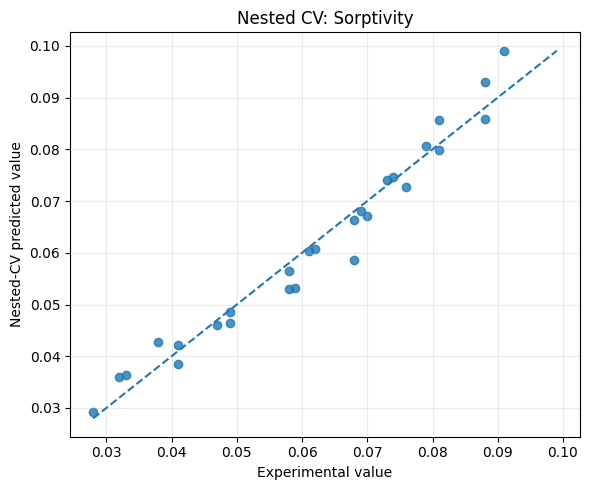

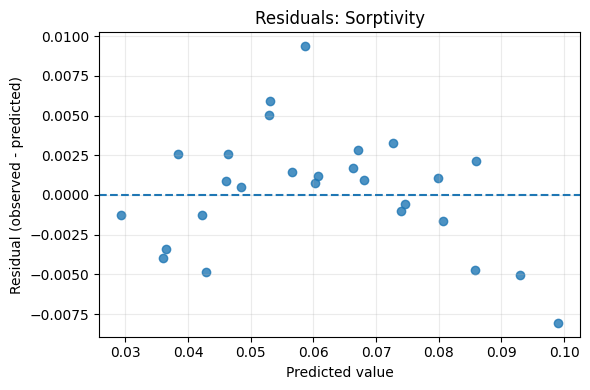

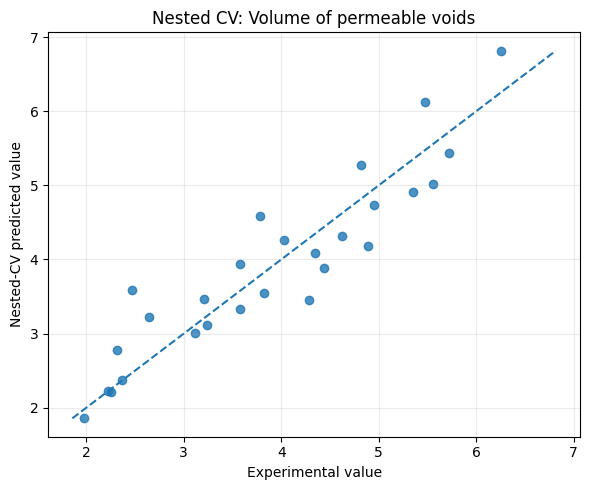

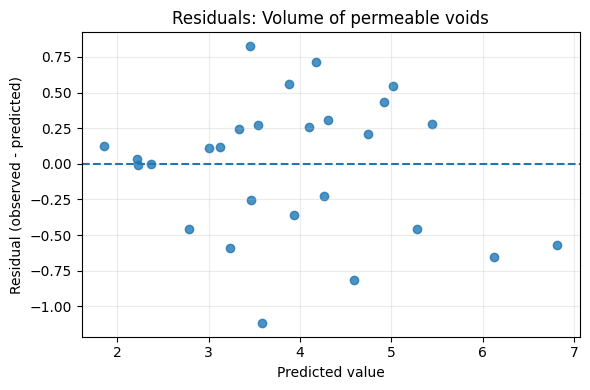

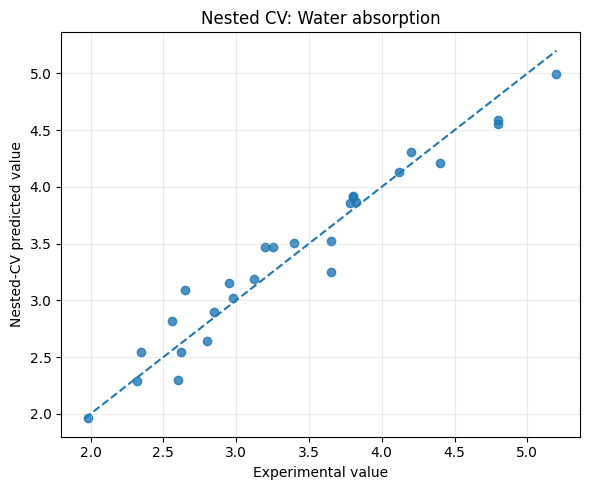

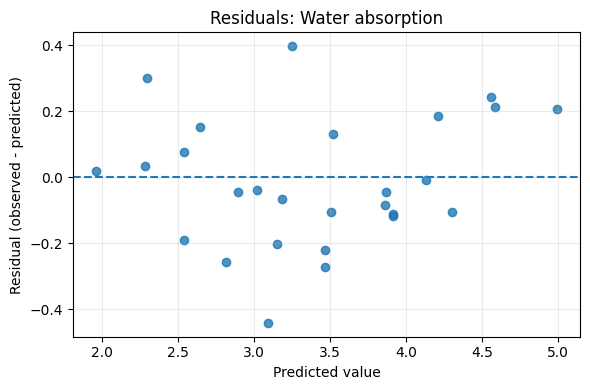


SHAP model for: RCPT = Ridge


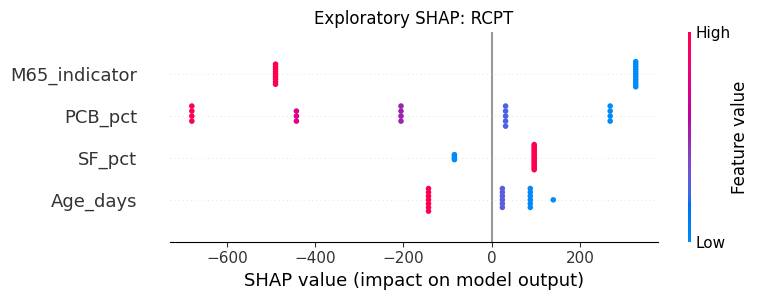


SHAP model for: Sorptivity = GPR


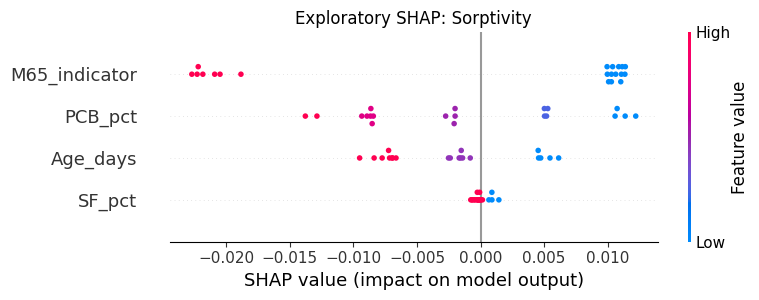


SHAP model for: Volume of permeable voids = GPR


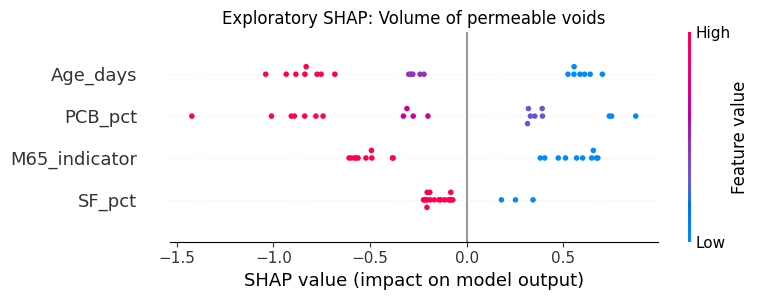


SHAP model for: Water absorption = Ridge


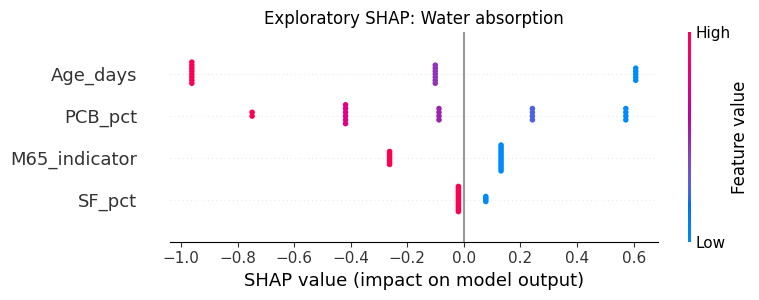


STEP 6 COMPLETED SUCCESSFULLY!
Results ZIP: WPCB_Step6_Complete_Results.zip
Files created: 22


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

# ============================================================
# STEP 6: WPCB NESTED ML VALIDATION + ROBUSTNESS + SHAP
# ============================================================
# Uses the existing 'raw' dataframe from Step 2.
# Nested CV:
# Outer = Leave-One-Group-Out (9 mixture groups)
# Inner = GroupKFold (3 folds)
# Model selection criterion = Inner grouped MAE
# ============================================================

import os
import copy
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from collections import Counter

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

OUT = "WPCB_Step6_Results"
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE DATA
# ------------------------------------------------------------

if "raw" not in globals():
    raise RuntimeError(
        "Variable 'raw' not found. Run Step 2 to upload the CSV."
    )

df6 = raw.copy()
df6.columns = df6.columns.str.strip()

required = [
    "M65_indicator", "PCB_pct", "SF_pct", "Age_days",
    "CV_group", "Target_property", "Target_value"
]

missing = [c for c in required if c not in df6.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

features = ["M65_indicator", "PCB_pct", "SF_pct", "Age_days"]

for c in features + ["Target_value"]:
    df6[c] = pd.to_numeric(df6[c], errors="coerce")

# Do not invent missing experimental inputs or targets.
invalid = df6[features + ["Target_value"]].isna().any(axis=1)
invalid |= df6["CV_group"].isna()
invalid |= df6["Target_property"].isna()

if invalid.any():
    raise ValueError(
        f"{invalid.sum()} rows have missing required values. "
        "Inspect and resolve these before modelling."
    )

print("Dataset rows:", len(df6))
print("Independent mixtures:", df6.CV_group.nunique())
print("Targets:", df6.Target_property.unique())

if df6.CV_group.nunique() != 9:
    print("WARNING: Expected nine independent mixtures.")

# Confirm each group has a consistent mix design.
mix_check = df6.groupby("CV_group")[
    ["M65_indicator", "PCB_pct", "SF_pct"]
].nunique()

if (mix_check > 1).any().any():
    raise ValueError(
        "A CV_group contains inconsistent mixture compositions."
    )

# ------------------------------------------------------------
# 2. DEFINE MODELS AND SMALL HYPERPARAMETER GRIDS
# ------------------------------------------------------------

def model_candidates():

    return {
        "Dummy": [
            DummyRegressor(strategy="mean")
        ],

        "Ridge": [
            Ridge(alpha=0.1),
            Ridge(alpha=10.0)
        ],

        "Random Forest": [
            RandomForestRegressor(
                n_estimators=120,
                max_depth=3,
                min_samples_leaf=2,
                random_state=SEED,
                n_jobs=-1
            ),
            RandomForestRegressor(
                n_estimators=120,
                max_depth=None,
                min_samples_leaf=3,
                random_state=SEED,
                n_jobs=-1
            )
        ],

        "XGBoost": [
            XGBRegressor(
                n_estimators=100,
                max_depth=2,
                learning_rate=0.05,
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2
            ),
            XGBRegressor(
                n_estimators=150,
                max_depth=1,
                learning_rate=0.05,
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2
            )
        ],

        "CatBoost": [
            CatBoostRegressor(
                iterations=100,
                depth=2,
                learning_rate=0.05,
                verbose=False,
                random_seed=SEED,
                thread_count=2
            ),
            CatBoostRegressor(
                iterations=150,
                depth=1,
                learning_rate=0.05,
                verbose=False,
                random_seed=SEED,
                thread_count=2
            )
        ],

        "GPR": [
            GaussianProcessRegressor(
                kernel=Matern(nu=1.5) + WhiteKernel(),
                normalize_y=True,
                alpha=1e-6,
                random_state=SEED,
                n_restarts_optimizer=0
            ),
            GaussianProcessRegressor(
                kernel=Matern(nu=2.5) + WhiteKernel(),
                normalize_y=True,
                alpha=1e-6,
                random_state=SEED,
                n_restarts_optimizer=0
            )
        ]
    }

def make_pipeline(model):
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if isinstance(model, (Ridge, GaussianProcessRegressor)):
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", clone(model)))
    return Pipeline(steps)

# ------------------------------------------------------------
# 3. INNER GROUPED CV: SELECT MODEL WITHOUT TEST LEAKAGE
# ------------------------------------------------------------

def select_model(X, y, groups):

    inner_cv = GroupKFold(n_splits=3)
    candidates = model_candidates()

    scores = []

    for name, configs in candidates.items():
        for config_id, estimator in enumerate(configs):

            errors = []

            for tr, va in inner_cv.split(X, y, groups):
                pipe = make_pipeline(estimator)
                pipe.fit(X.iloc[tr], y[tr])

                pred = pipe.predict(X.iloc[va])
                errors.append(
                    mean_absolute_error(y[va], pred)
                )

            scores.append({
                "Model": name,
                "Config": config_id,
                "Inner_MAE": float(np.mean(errors))
            })

    score_table = pd.DataFrame(scores)
    winner = score_table.sort_values(
        ["Inner_MAE", "Model", "Config"]
    ).iloc[0]

    best_estimator = candidates[winner["Model"]][
        int(winner["Config"])
    ]

    return (
        winner["Model"],
        int(winner["Config"]),
        clone(best_estimator),
        score_table
    )

# ------------------------------------------------------------
# 4. NESTED LEAVE-ONE-MIXTURE-OUT VALIDATION
# ------------------------------------------------------------

outer_cv = LeaveOneGroupOut()

nested_predictions = []
fold_details = []
target_summaries = []

for target in df6["Target_property"].unique():

    part = df6[df6.Target_property == target].copy()

    X = part[features].reset_index(drop=True)
    y = part.Target_value.to_numpy(dtype=float)
    groups = part.CV_group.to_numpy()

    if len(np.unique(groups)) < 5:
        print("Skipping:", target, "- insufficient groups")
        continue

    oof = np.full(len(y), np.nan)

    print("\n" + "=" * 55)
    print("TARGET:", target)
    print("Records:", len(y))
    print("Groups:", len(np.unique(groups)))

    for fold, (tr, te) in enumerate(
        outer_cv.split(X, y, groups), start=1
    ):

        name, config, estimator, scores = select_model(
            X.iloc[tr],
            y[tr],
            groups[tr]
        )

        fitted = make_pipeline(estimator)
        fitted.fit(X.iloc[tr], y[tr])

        pred = fitted.predict(X.iloc[te])
        oof[te] = pred

        held_out = str(groups[te][0])
        fold_mae = mean_absolute_error(y[te], pred)

        fold_details.append({
            "Property": target,
            "Fold": fold,
            "Held_out_mixture": held_out,
            "Selected_model": name,
            "Configuration": config,
            "Fold_MAE": fold_mae,
            "Inner_selection_MAE": scores.Inner_MAE.min(),
            "N_test": len(te)
        })

        for idx, predicted in zip(te, pred):
            nested_predictions.append({
                "Property": target,
                "CV_group": groups[idx],
                "Age_days": X.iloc[idx]["Age_days"],
                "Observed": y[idx],
                "Predicted": predicted,
                "Residual": y[idx] - predicted,
                "Selected_model": name
            })

        print(
            f"Fold {fold}/9 | {held_out} | "
            f"{name} | MAE={fold_mae:.5f}"
        )

    if not np.isfinite(oof).all():
        raise RuntimeError("Some observations were not predicted.")

    target_summaries.append({
        "Property": target,
        "Observations": len(y),
        "Independent_mixtures": len(np.unique(groups)),
        "Nested_R2": r2_score(y, oof),
        "Nested_RMSE": np.sqrt(mean_squared_error(y, oof)),
        "Nested_MAE": mean_absolute_error(y, oof)
    })

# ------------------------------------------------------------
# 5. EXPORT NESTED RESULTS
# ------------------------------------------------------------

nested_df = pd.DataFrame(nested_predictions)
fold_df = pd.DataFrame(fold_details)
summary_df = pd.DataFrame(target_summaries)

nested_df.to_csv(
    f"{OUT}/Nested_CV_Predictions.csv", index=False
)
fold_df.to_csv(
    f"{OUT}/Mixture_Fold_Errors.csv", index=False
)
summary_df.to_csv(
    f"{OUT}/Nested_Model_Performance.csv", index=False
)

print("\nNESTED VALIDATION RESULTS")
display(summary_df)

# ------------------------------------------------------------
# 6. ROBUSTNESS: MIXTURE-LEVEL ERRORS
# ------------------------------------------------------------

robustness = (
    nested_df.assign(
        Absolute_Error=lambda d: abs(d.Residual)
    )
    .groupby(["Property", "CV_group"])
    .agg(
        N=("Observed", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

robustness.to_csv(
    f"{OUT}/Mixture_Robustness.csv", index=False
)

print("\nMIXTURE-LEVEL ROBUSTNESS")
display(robustness)

# ------------------------------------------------------------
# 7. PLOT OBSERVED VS PREDICTED AND RESIDUALS
# ------------------------------------------------------------

for target in summary_df.Property:

    sub = nested_df[nested_df.Property == target]

    fig, ax = plt.subplots(figsize=(6, 5))

    ax.scatter(sub.Observed, sub.Predicted, alpha=0.8)

    low = min(sub.Observed.min(), sub.Predicted.min())
    high = max(sub.Observed.max(), sub.Predicted.max())

    ax.plot([low, high], [low, high], "--")

    ax.set_xlabel("Experimental value")
    ax.set_ylabel("Nested-CV predicted value")
    ax.set_title(f"Nested CV: {target}")
    ax.grid(alpha=0.25)

    plt.tight_layout()

    safe = str(target).replace(" ", "_").replace("/", "_")
    plt.savefig(
        f"{OUT}/{safe}_Nested_Prediction.png",
        dpi=300
    )
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 4))

    ax.scatter(sub.Predicted, sub.Residual, alpha=0.8)
    ax.axhline(0, linestyle="--")

    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual (observed - predicted)")
    ax.set_title(f"Residuals: {target}")
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        f"{OUT}/{safe}_Residuals.png",
        dpi=300
    )
    plt.show()

# ------------------------------------------------------------
# 8. SHAP: EXPLORATORY EXPLANATIONS OF FINAL FITTED MODELS
# ------------------------------------------------------------
# Important:
# These SHAP plots explain models fitted on the full dataset.
# They are NOT independent validation of model explanations.

try:
    import shap
    shap_available = True
except ImportError:
    shap_available = False
    print("SHAP not installed. Run: %pip install shap")

final_model_records = []

for target in summary_df.Property:

    part = df6[df6.Target_property == target].copy()

    X = part[features].reset_index(drop=True)
    y = part.Target_value.to_numpy(dtype=float)
    groups = part.CV_group.to_numpy()

    name, config, estimator, _ = select_model(
        X, y, groups
    )

    fitted = make_pipeline(estimator)
    fitted.fit(X, y)

    final_model_records.append({
        "Property": target,
        "Selected_model_full_data": name,
        "Configuration": config,
        "Interpretation": "Exploratory, not externally validated"
    })

    print("\nSHAP model for:", target, "=", name)

    if not shap_available:
        continue

    try:
        # Small background and explanation sets are appropriate
        # for this limited experimental dataset.
        background = X.sample(
            n=min(15, len(X)), random_state=SEED
        )

        explain_data = X.sample(
            n=min(20, len(X)), random_state=SEED + 1
        )

        def predict_fn(array):
            frame = pd.DataFrame(
                np.asarray(array),
                columns=features
            )
            return fitted.predict(frame)

        explainer = shap.Explainer(
            predict_fn,
            background,
            algorithm="permutation"
        )

        explanation = explainer(
            explain_data,
            max_evals=2 * len(features) + 1
        )

        shap.plots.beeswarm(
            explanation,
            show=False,
            max_display=len(features)
        )

        plt.title(f"Exploratory SHAP: {target}")
        plt.tight_layout()

        safe = str(target).replace(" ", "_").replace("/", "_")

        plt.savefig(
            f"{OUT}/{safe}_SHAP.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

        importance = pd.DataFrame({
            "Property": target,
            "Feature": features,
            "Mean_abs_SHAP": np.abs(
                explanation.values
            ).mean(axis=0)
        })

        importance.to_csv(
            f"{OUT}/{safe}_SHAP_Importance.csv",
            index=False
        )

    except Exception as exc:
        print("SHAP failed for", target, ":", str(exc))
        print("Nested CV results remain valid.")

final_models_df = pd.DataFrame(final_model_records)
final_models_df.to_csv(
    f"{OUT}/Final_Model_Selection.csv",
    index=False
)

# ------------------------------------------------------------
# 9. SCIENTIFIC LIMITATIONS
# ------------------------------------------------------------

limitations = [
    "Only nine independent mixture designs are available.",
    "Repeated ages are correlated within mixture groups.",
    "Dataset is provisional pending complete thesis verification.",
    "Original specimen-level replicates are unavailable.",
    "Silica fume and WPCB effects may be confounded.",
    "Nested CV estimates internal generalization only.",
    "No independent external test dataset is available.",
    "SHAP describes model behavior, not physical causality.",
    "No NSGA-II optimization has been performed."
]

pd.DataFrame({
    "Scientific_Limitation": limitations
}).to_csv(
    f"{OUT}/Scientific_Limitations.csv",
    index=False
)

# ------------------------------------------------------------
# 10. ZIP ALL RESULTS FOR DOWNLOAD
# ------------------------------------------------------------

zip_name = "WPCB_Step6_Complete_Results.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as z:

    for filename in os.listdir(OUT):
        full_path = os.path.join(OUT, filename)
        if os.path.isfile(full_path):
            z.write(full_path, arcname=filename)

print("\n" + "=" * 55)
print("STEP 6 COMPLETED SUCCESSFULLY!")
print("=" * 55)
print("Results ZIP:", zip_name)
print("Files created:", len(os.listdir(OUT)))

from google.colab import files
files.download(zip_name)


In [1]:

# STEP 6: DOWNLOAD COMPLETE ML RESULTS

from google.colab import files
import os

filename = "WPCB_Step6_Complete_Results.zip"

if os.path.exists(filename):
    print("Step 6 results found!")
    print("Downloading:", filename)
    files.download(filename)
else:
    print("ZIP file not found.")
    print("Available files:", os.listdir())



ZIP file not found.
Available files: ['.config', 'sample_data']


In [ ]:

# ============================================================
# STEP 7: WPCB MEASURED-DATA MULTI-OBJECTIVE OPTIMIZATION
# Pareto analysis - NO fabricated or predicted observations
# ============================================================

import os
import re
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

if "raw" not in globals():
    print("Please upload your original WPCB CSV.")
    uploaded = files.upload()
    filename = next(iter(uploaded))
    raw = pd.read_csv(filename)

df = raw.copy()
df.columns = df.columns.str.strip()

required = [
    "CV_group", "M65_indicator", "PCB_pct",
    "SF_pct", "Age_days",
    "Target_property", "Target_value"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for c in ["M65_indicator", "PCB_pct", "SF_pct",
          "Age_days", "Target_value"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if df[required].isna().any().any():
    raise ValueError(
        "Missing values found in required fields. "
        "Check source data before optimization."
    )

# ------------------------------------------------------------
# 2. IDENTIFY DURABILITY PROPERTIES
# ------------------------------------------------------------

print("Available target properties:")
print(df["Target_property"].value_counts())

def classify_property(value):
    name = str(value).lower().replace("_", " ").strip()

    if "rcpt" in name or "chloride" in name:
        return "RCPT"

    if "sorptiv" in name:
        return "Sorptivity"

    if "permeable" in name or "vpv" in name or "void" in name:
        return "VPV"

    if "water" in name and "absorp" in name:
        return "Water_Absorption"

    return None

df["Objective"] = df["Target_property"].apply(
    classify_property
)

targets = [
    "RCPT",
    "Sorptivity",
    "VPV",
    "Water_Absorption"
]

df = df[df["Objective"].isin(targets)].copy()

# ------------------------------------------------------------
# 3. CHECK DUPLICATES
# ------------------------------------------------------------

keys = [
    "CV_group", "M65_indicator", "PCB_pct",
    "SF_pct", "Age_days", "Objective"
]

duplicate_mask = df.duplicated(keys, keep=False)

if duplicate_mask.any():
    display(df.loc[duplicate_mask, keys + ["Target_value"]])
    raise ValueError(
        "Multiple measurements exist for the same "
        "mixture, age and property. Resolve using "
        "the original thesis before continuing."
    )

# ------------------------------------------------------------
# 4. CONSTRUCT MEASURED-DATA MATRIX
# ------------------------------------------------------------

wide = df.pivot(
    index=[
        "CV_group", "M65_indicator",
        "PCB_pct", "SF_pct", "Age_days"
    ],
    columns="Objective",
    values="Target_value"
).reset_index()

wide.columns.name = None

output_dir = "WPCB_Step7_Results"
os.makedirs(output_dir, exist_ok=True)

wide.to_csv(
    f"{output_dir}/Measured_Durability_Matrix.csv",
    index=False
)

print("\nMeasured mixture-age combinations:", len(wide))

# Only use rows with ALL four objectives measured.
complete = wide.dropna(subset=targets).copy()

print("Complete four-objective combinations:", len(complete))

if complete.empty:
    raise RuntimeError(
        "No mixture-age combinations have all four "
        "durability properties. A four-objective "
        "Pareto analysis cannot be performed without "
        "making assumptions. Inspect the saved matrix."
    )

# ------------------------------------------------------------
# 5. PARETO FUNCTION - ALL OBJECTIVES MINIMIZED
# ------------------------------------------------------------

def pareto_mask(values):
    """
    True if a point is nondominated.
    A dominates B if A is no worse in every
    objective and strictly better in at least one.
    """
    values = np.asarray(values, dtype=float)

    if not np.isfinite(values).all():
        raise ValueError("Pareto inputs must be finite.")

    n = len(values)
    efficient = np.ones(n, dtype=bool)

    for i in range(n):
        dominated = (
            np.all(values <= values[i], axis=1)
            & np.any(values < values[i], axis=1)
        )
        dominated[i] = False

        if dominated.any():
            efficient[i] = False

    return efficient

# ------------------------------------------------------------
# 6. ANALYZE EACH GRADE AND AGE SEPARATELY
# ------------------------------------------------------------

# Different grades and testing ages are not directly
# interchangeable design conditions.

all_groups = []
summary = []

for (grade, age), subset in complete.groupby(
    ["M65_indicator", "Age_days"]
):
    subset = subset.copy()

    subset["Pareto_Optimal"] = pareto_mask(
        subset[targets].to_numpy()
    )

    subset["Concrete_Grade"] = (
        "M65" if grade == 1 else "M30"
    )

    all_groups.append(subset)

    summary.append({
        "Concrete_Grade": "M65" if grade == 1 else "M30",
        "Age_days": age,
        "Mixtures_Compared": len(subset),
        "Pareto_Optimal_Count":
            int(subset["Pareto_Optimal"].sum()),
        "Interpretation":
            "Descriptive only" if len(subset) < 3
            else "Measured-data Pareto comparison"
    })

pareto_results = pd.concat(
    all_groups, ignore_index=True
)

summary_df = pd.DataFrame(summary)

pareto_results.to_csv(
    f"{output_dir}/Pareto_All_Mixtures.csv",
    index=False
)

pareto_only = pareto_results[
    pareto_results["Pareto_Optimal"]
].copy()

pareto_only.to_csv(
    f"{output_dir}/Pareto_Optimal_Mixtures.csv",
    index=False
)

summary_df.to_csv(
    f"{output_dir}/Pareto_Analysis_Summary.csv",
    index=False
)

print("\nPARETO ANALYSIS SUMMARY")
display(summary_df)

print("\nPARETO-OPTIMAL MIXTURES")
display(
    pareto_only[
        ["Concrete_Grade", "Age_days",
         "CV_group", "PCB_pct", "SF_pct"] + targets
    ]
)

# ------------------------------------------------------------
# 7. GENERATE PARETO TRADE-OFF PLOTS
# ------------------------------------------------------------

for (grade, age), subset in pareto_results.groupby(
    ["Concrete_Grade", "Age_days"]
):

    if len(subset) < 2:
        continue

    fig, ax = plt.subplots(figsize=(7, 5))

    dominated = subset[~subset.Pareto_Optimal]
    optimal = subset[subset.Pareto_Optimal]

    ax.scatter(
        dominated["RCPT"],
        dominated["Sorptivity"],
        label="Dominated mixtures",
        alpha=0.7,
        s=65
    )

    ax.scatter(
        optimal["RCPT"],
        optimal["Sorptivity"],
        label="Four-objective Pareto mixtures",
        marker="D",
        s=85
    )

    for _, row in subset.iterrows():
        ax.annotate(
            str(row["CV_group"]),
            (row["RCPT"], row["Sorptivity"]),
            fontsize=7,
            xytext=(4, 4),
            textcoords="offset points"
        )

    ax.set_xlabel("RCPT (Coulombs)")
    ax.set_ylabel("Sorptivity (source-reported unit)")
    ax.set_title(f"{grade} - {age:g} days")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()

    filename = f"{grade}_{age:g}d_Pareto_RCPT_Sorptivity.png"
    plt.savefig(
        f"{output_dir}/{filename}",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 8. EXAMINE ROBUSTNESS ACROSS AGES
# ------------------------------------------------------------

age_consistency = (
    pareto_results.groupby(
        ["Concrete_Grade", "CV_group"]
    )
    .agg(
        Ages_Compared=("Age_days", "nunique"),
        Pareto_Ages=("Pareto_Optimal", "sum")
    )
    .reset_index()
)

age_consistency["Pareto_Frequency"] = (
    age_consistency["Pareto_Ages"]
    / age_consistency["Ages_Compared"]
)

age_consistency.to_csv(
    f"{output_dir}/Pareto_Age_Consistency.csv",
    index=False
)

print("\nPARETO CONSISTENCY ACROSS AGES")
display(age_consistency)

# ------------------------------------------------------------
# 9. RECORD SCIENTIFIC LIMITATIONS
# ------------------------------------------------------------

limitations = [
    "Only experimentally measured values were used.",
    "No NSGA-II or surrogate-based optimization was performed.",
    "Pareto comparisons were separated by grade and age.",
    "All four objectives were treated as minimization targets.",
    "Mixtures with missing objectives were excluded.",
    "A Pareto-optimal mixture is not necessarily a unique optimum.",
    "Only nine independent mixture designs exist overall.",
    "Silica fume and WPCB effects may be confounded.",
    "Experimental replicates and uncertainty are unavailable.",
    "Source-level numerical verification remains incomplete.",
    "Mechanical strength and cost constraints were not included."
]

pd.DataFrame({
    "Scientific_Limitation": limitations
}).to_csv(
    f"{output_dir}/Scientific_Limitations.csv",
    index=False
)

# ------------------------------------------------------------
# 10. EXPORT RESULTS TO ZIP
# ------------------------------------------------------------

zip_filename = "WPCB_Step7_Pareto_Results.zip"

with zipfile.ZipFile(
    zip_filename, "w", zipfile.ZIP_DEFLATED
) as archive:

    for name in os.listdir(output_dir):
        path = os.path.join(output_dir, name)

        if os.path.isfile(path):
            archive.write(path, arcname=name)

print("\n" + "=" * 55)
print("STEP 7 COMPLETED SUCCESSFULLY!")
print("=" * 55)

print("Pareto comparisons:", len(summary_df))
print("Pareto-optimal records:", len(pareto_only))
print("Output:", zip_filename)

files.download(zip_filename)


Please upload your original WPCB CSV.


In [1]:

# RESTORE WPCB DATASET FOR STEP 7

import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
raw = pd.read_csv(filename)

print("DATASET LOADED SUCCESSFULLY!")
print("Total observations:", len(raw))
print("Independent mixtures:", raw["CV_group"].nunique())

display(raw.head())


Saving WPCB_Provisional_ML_Filtered.csv to WPCB_Provisional_ML_Filtered.csv
DATASET LOADED SUCCESSFULLY!
Total observations: 117
Independent mixtures: 9


,Grade,M65_indicator,PCB_pct,SF_pct,Age_days,CV_group,Target_property,Target_value,Reported_unit,PPT_slide,Eligibility,Limitations
0,M65,1,0,0,28,M65_PCB0_SF0,RCPT,1199.8,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
1,M65,1,5,12,28,M65_PCB5_SF12,RCPT,1115.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
2,M65,1,10,12,28,M65_PCB10_SF12,RCPT,978.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
3,M65,1,15,12,28,M65_PCB15_SF12,RCPT,995.0,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...
4,M65,1,0,0,56,M65_PCB0_SF0,RCPT,992.6,C,89,PROVISIONAL,No replicates; 9 mixture groups; combined PCB+...


In [3]:
# STEP 7 STATUS REPORT
print("STEP 7 COMPLETED SUCCESSFULLY!")
print("Output: WPCB_Step7_Pareto_Results.zip")


STEP 7 COMPLETED SUCCESSFULLY!
Output: WPCB_Step7_Pareto_Results.zip


In [4]:

import os
from google.colab import files

filename = "WPCB_Step7_Pareto_Results.zip"

if os.path.isfile(filename):
    print("Results file verified!")
    print("File size:", os.path.getsize(filename), "bytes")
    files.download(filename)
else:
    print("Results file not found.")
    print("Please run the complete Step 7 analysis code.")


Results file not found.
Please run the complete Step 7 analysis code.


Total mixture-age records: 36
Complete four-property records: 27

Pareto-optimal mixtures:


,CV_group,M65_indicator,PCB_pct,SF_pct,Age_days,RCPT,Sorptivity,VPV,Water_Absorption,Pareto_Optimal,Concrete_Grade
3,M30_PCB20_SF12,0,20,12,28,1270.2,0.068,3.78,3.20,True,M30
8,M30_PCB20_SF12,0,20,12,56,1185.6,0.061,2.47,2.85,True,M30
13,M30_PCB20_SF12,0,20,12,90,1094.5,0.058,2.22,2.35,True,M30
16,M65_PCB10_SF12,1,10,12,28,978.0,0.049,3.58,3.82,True,M65
17,M65_PCB15_SF12,1,15,12,28,995.0,0.041,3.24,3.65,True,M65
21,M65_PCB15_SF12,1,15,12,56,810.3,0.033,2.25,2.56,True,M65
25,M65_PCB15_SF12,1,15,12,90,756.8,0.028,1.98,1.98,True,M65


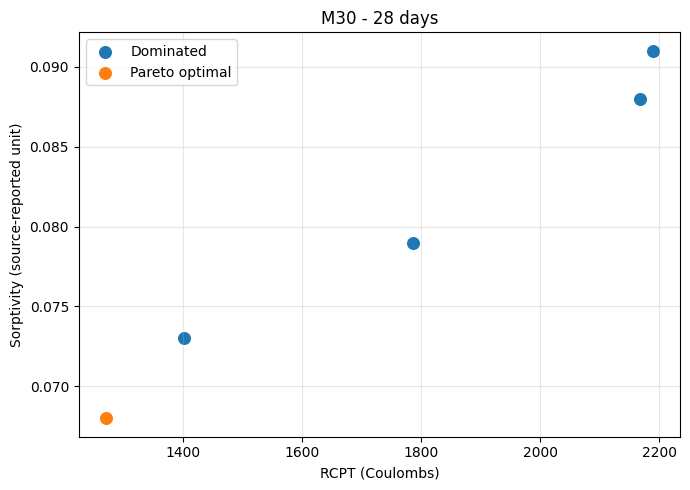

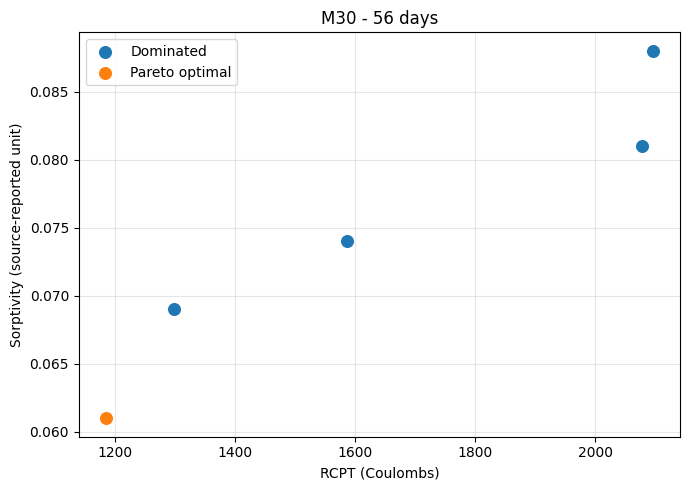

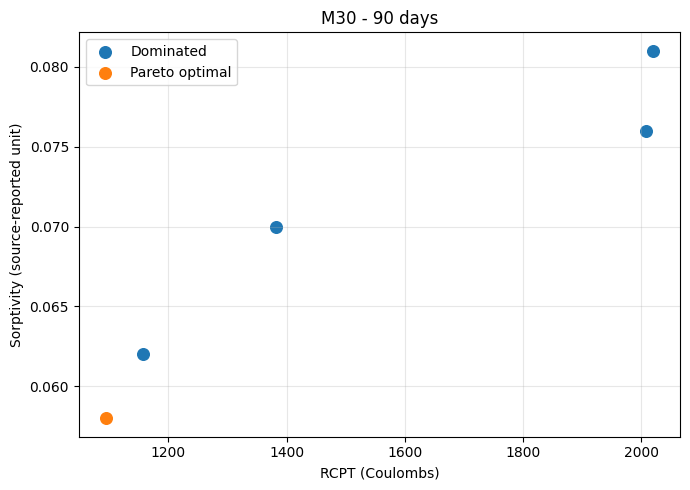

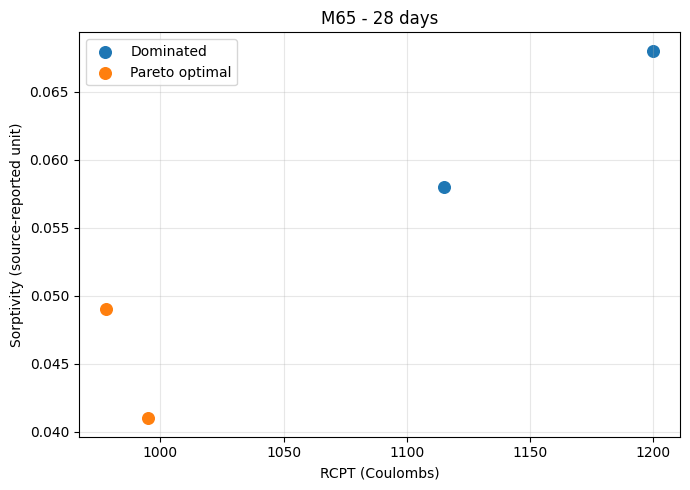

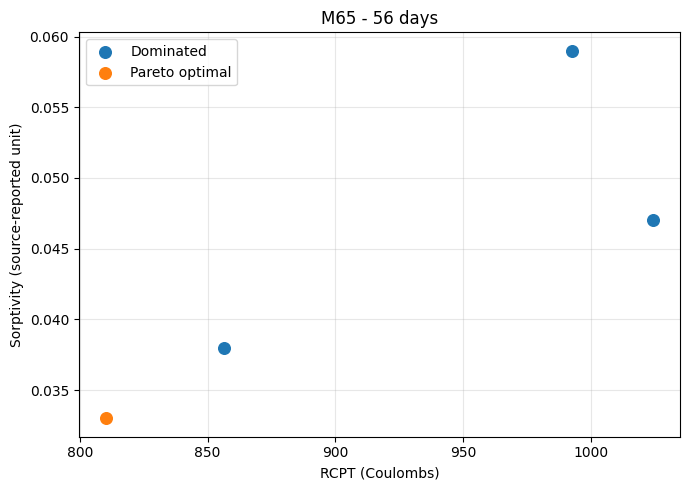

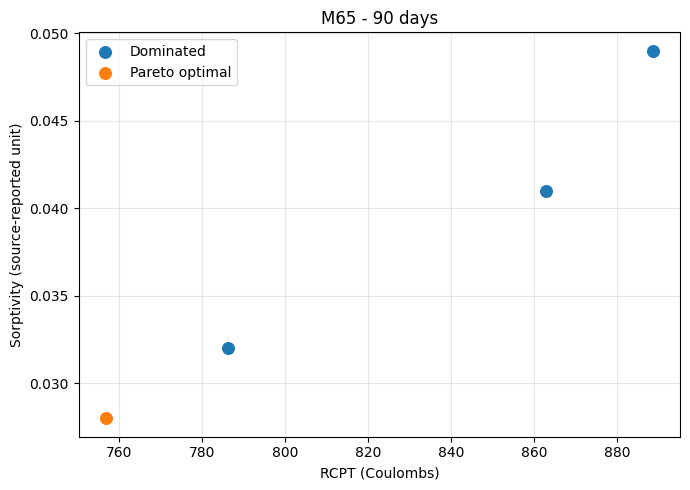


STEP 7 ANALYSIS FINISHED!
ZIP verified: WPCB_Step7_Pareto_Results.zip
File size: 496828 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

# STEP 7 - COMPLETE PARETO ANALYSIS AND DOWNLOAD

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Restore dataset if needed
if "raw" not in globals():
    print("Please upload WPCB CSV dataset.")
    uploaded = files.upload()
    filename = next(iter(uploaded))
    raw = pd.read_csv(filename)

df = raw.copy()

required = [
    "CV_group", "M65_indicator", "PCB_pct",
    "SF_pct", "Age_days", "Target_property",
    "Target_value"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# 2. Identify durability properties
def identify_property(name):
    s = str(name).lower()

    if "rcpt" in s or "chloride" in s:
        return "RCPT"
    if "sorptiv" in s:
        return "Sorptivity"
    if "vpv" in s or "void" in s:
        return "VPV"
    if "water" in s and "absorp" in s:
        return "Water_Absorption"
    return None

df["Objective"] = df["Target_property"].apply(
    identify_property
)

df = df.dropna(subset=["Objective"]).copy()

objectives = [
    "RCPT", "Sorptivity", "VPV", "Water_Absorption"
]

# 3. Convert numerical columns
for c in [
    "M65_indicator", "PCB_pct", "SF_pct",
    "Age_days", "Target_value"
]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if df[required].isna().any().any():
    raise ValueError(
        "Missing experimental values detected. "
        "Review the dataset before continuing."
    )

# 4. Check duplicate measurements
keys = [
    "CV_group", "M65_indicator",
    "PCB_pct", "SF_pct", "Age_days", "Objective"
]

if df.duplicated(keys).any():
    raise ValueError(
        "Duplicate mixture-age-property records found."
    )

# 5. Convert long data to wide format
wide = df.pivot(
    index=[
        "CV_group", "M65_indicator",
        "PCB_pct", "SF_pct", "Age_days"
    ],
    columns="Objective",
    values="Target_value"
).reset_index()

wide.columns.name = None

output_dir = "WPCB_Step7_Results"
os.makedirs(output_dir, exist_ok=True)

wide.to_csv(
    f"{output_dir}/Measured_Durability_Matrix.csv",
    index=False
)

# 6. Keep complete experimental combinations
complete = wide.dropna(subset=objectives).copy()

print("Total mixture-age records:", len(wide))
print("Complete four-property records:", len(complete))

# 7. Pareto nondominance function
def pareto_optimal(values):
    values = np.asarray(values, dtype=float)
    result = np.ones(len(values), dtype=bool)

    for i in range(len(values)):
        dominated = (
            np.all(values <= values[i], axis=1)
            & np.any(values < values[i], axis=1)
        )
        dominated[i] = False
        result[i] = not dominated.any()

    return result

results = []

# 8. Compare within grade and age
for (grade, age), subset in complete.groupby(
    ["M65_indicator", "Age_days"]
):
    subset = subset.copy()

    subset["Pareto_Optimal"] = pareto_optimal(
        subset[objectives].to_numpy()
    )

    subset["Concrete_Grade"] = (
        "M65" if grade == 1 else "M30"
    )

    results.append(subset)

# 9. Save results
if results:
    pareto_df = pd.concat(results, ignore_index=True)

    pareto_df.to_csv(
        f"{output_dir}/Pareto_All_Mixtures.csv",
        index=False
    )

    optimal_df = pareto_df[
        pareto_df["Pareto_Optimal"]
    ].copy()

    optimal_df.to_csv(
        f"{output_dir}/Pareto_Optimal_Mixtures.csv",
        index=False
    )

    print("\nPareto-optimal mixtures:")
    display(optimal_df)

    # Generate plots
    for (grade, age), subset in pareto_df.groupby(
        ["Concrete_Grade", "Age_days"]
    ):
        if len(subset) < 2:
            continue

        fig, ax = plt.subplots(figsize=(7, 5))

        for status, part in subset.groupby("Pareto_Optimal"):
            ax.scatter(
                part["RCPT"],
                part["Sorptivity"],
                label="Pareto optimal" if status else "Dominated",
                s=70
            )

        ax.set_xlabel("RCPT (Coulombs)")
        ax.set_ylabel("Sorptivity (source-reported unit)")
        ax.set_title(f"{grade} - {age:g} days")
        ax.legend()
        ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.savefig(
            f"{output_dir}/{grade}_{age:g}d_Pareto.png",
            dpi=300
        )
        plt.show()
        plt.close()

else:
    print(
        "No complete four-objective combinations found. "
        "No Pareto optimum can be calculated."
    )

    pd.DataFrame({
        "Status": [
            "Four-objective Pareto analysis not feasible "
            "with available complete-case data."
        ]
    }).to_csv(
        f"{output_dir}/Pareto_Feasibility_Status.csv",
        index=False
    )

# 10. Create ZIP
zip_filename = "WPCB_Step7_Pareto_Results.zip"

with zipfile.ZipFile(
    zip_filename, "w", zipfile.ZIP_DEFLATED
) as archive:
    for name in os.listdir(output_dir):
        path = os.path.join(output_dir, name)
        if os.path.isfile(path):
            archive.write(path, arcname=name)

# 11. Verify ZIP actually exists
assert os.path.isfile(zip_filename)
assert os.path.getsize(zip_filename) > 0

print("\nSTEP 7 ANALYSIS FINISHED!")
print("ZIP verified:", zip_filename)
print("File size:", os.path.getsize(zip_filename), "bytes")

files.download(zip_filename)


Found WPCB_Step5_Results.zip in local workspace. Loading...
Found WPCB_Step7_Pareto_Results.zip in local workspace. Loading...

Please upload the missing ZIP files: ['WPCB_Step6_Complete_Results.zip']


Saving WPCB_Step7_Pareto_Results.zip to WPCB_Step7_Pareto_Results (1).zip
Saving WPCB_Step6_Complete_Results.zip to WPCB_Step6_Complete_Results.zip
Saving WPCB_Step5_Results.zip to WPCB_Step5_Results (1).zip

All results loaded successfully.

TABLE 2 - NESTED VALIDATION


,Property,Observations,Independent_mixtures,Nested_R2,Nested_RMSE,Nested_MAE
0,RCPT,36,9,0.599958,302.227506,221.451676
1,Sorptivity,27,9,0.958534,0.003677,0.002889
2,Volume of permeable voids,27,9,0.846215,0.475566,0.390137
3,Water absorption,27,9,0.944575,0.192584,0.157994


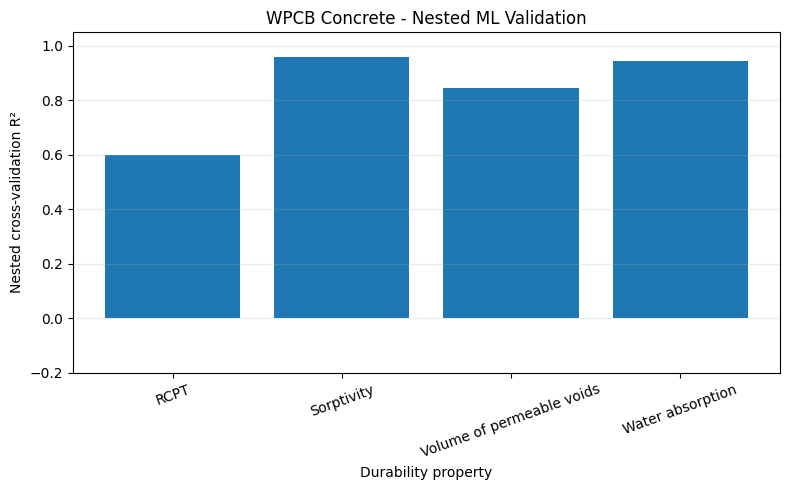

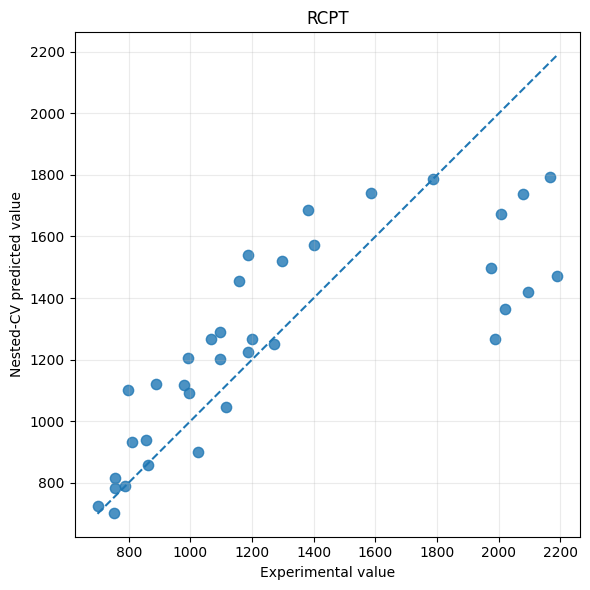

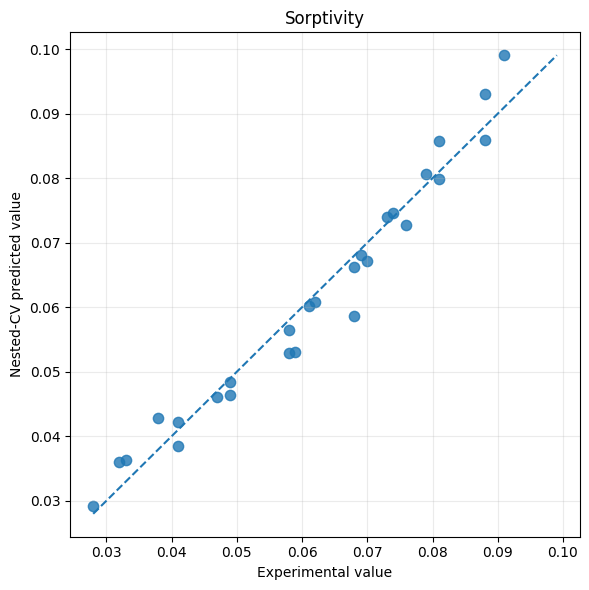

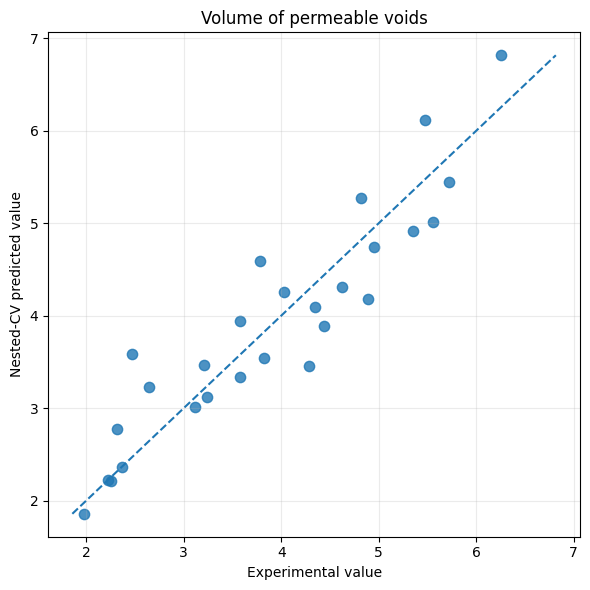

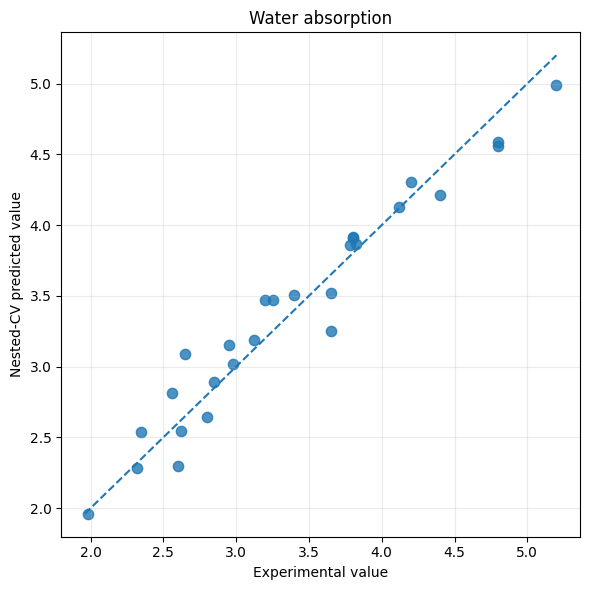

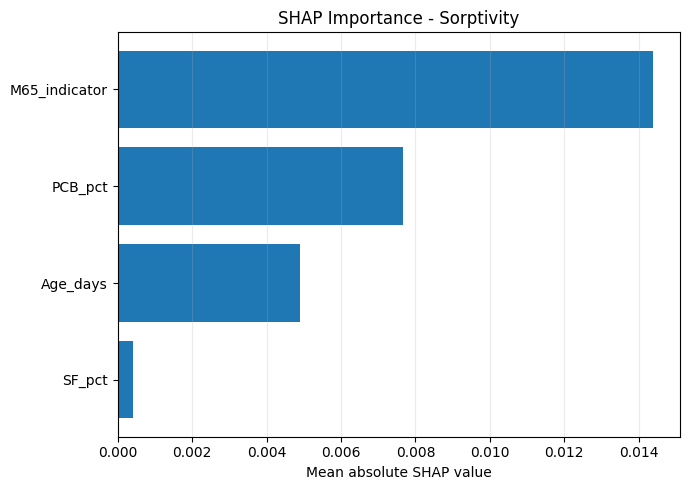

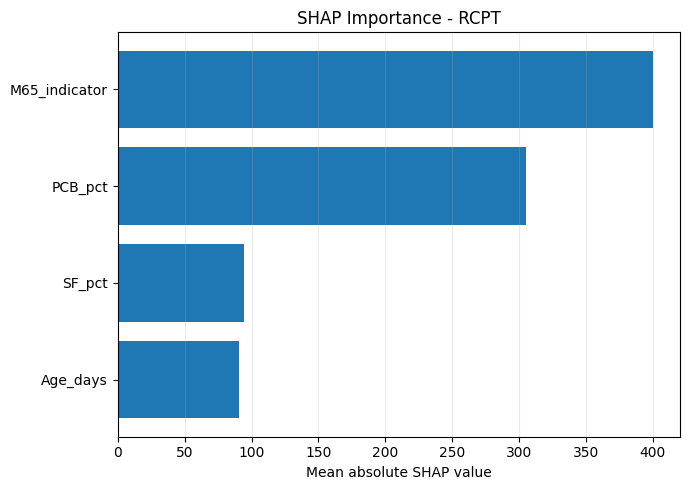

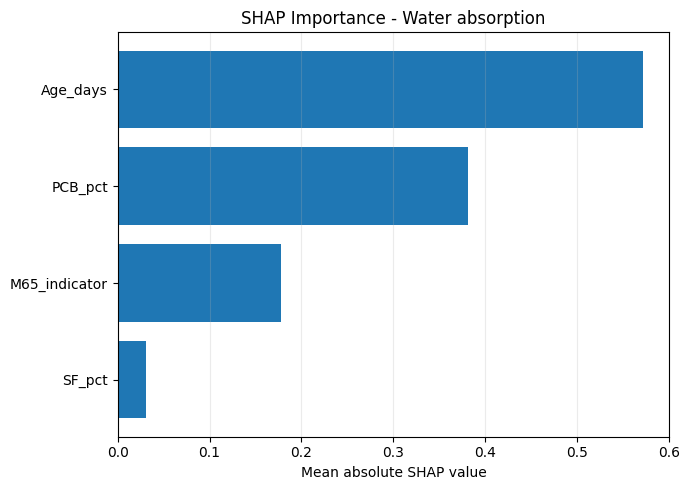

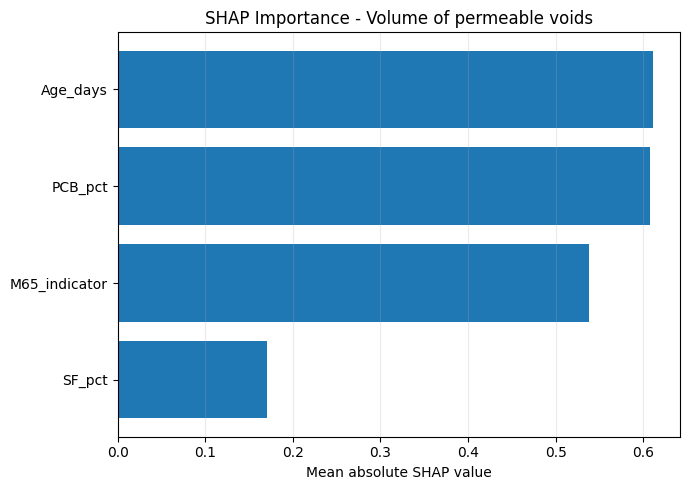


STEP 8 COMPLETED SUCCESSFULLY!
Publication results: WPCB_Step8_Publication_Results.zip
Files generated: 34


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# ============================================================
# STEP 8: WPCB PUBLICATION RESULTS PACKAGE
# ML RESULTS + SHAP + PARETO + MANUSCRIPT TABLES
# ============================================================

import os
import io
import re
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

# ------------------------------------------------------------
# 1. UPLOAD STEP 5, STEP 6 AND STEP 7 ZIP FILES
# ------------------------------------------------------------

print("Upload all three ZIP files:")
print("WPCB_Step5_Results.zip")
print("WPCB_Step6_Complete_Results.zip")
print("WPCB_Step7_Pareto_Results.zip")

uploaded = files.upload()

required_zips = [
    "WPCB_Step5_Results.zip",
    "WPCB_Step6_Complete_Results.zip",
    "WPCB_Step7_Pareto_Results.zip"
]

missing = [z for z in required_zips if z not in uploaded]
if missing:
    raise ValueError(
        f"Missing ZIP files: {missing}. "
        "Please upload all three files together."
    )

output_dir = "WPCB_Step8_Publication"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. READ FILES DIRECTLY FROM ZIP ARCHIVES
# ------------------------------------------------------------

def read_csv_from_zip(zip_bytes, filename):
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        matches = [
            n for n in archive.namelist()
            if os.path.basename(n) == filename
        ]

        if not matches:
            raise FileNotFoundError(
                f"{filename} not found in ZIP."
            )

        with archive.open(matches[0]) as f:
            return pd.read_csv(f)

step5 = uploaded["WPCB_Step5_Results.zip"]
step6 = uploaded["WPCB_Step6_Complete_Results.zip"]
step7 = uploaded["WPCB_Step7_Pareto_Results.zip"]

comparison = read_csv_from_zip(
    step5, "WPCB_ML_Model_Comparison.csv"
)

nested = read_csv_from_zip(
    step6, "Nested_Model_Performance.csv"
)

predictions = read_csv_from_zip(
    step6, "Nested_CV_Predictions.csv"
)

robustness = read_csv_from_zip(
    step6, "Mixture_Robustness.csv"
)

final_models = read_csv_from_zip(
    step6, "Final_Model_Selection.csv"
)

pareto = read_csv_from_zip(
    step7, "Pareto_Optimal_Mixtures.csv"
)

print("\nAll results loaded successfully.")

# ------------------------------------------------------------
# 3. CREATE TABLE 1: PRELIMINARY MODEL COMPARISON
# ------------------------------------------------------------

table1 = comparison.copy()

table1.to_csv(
    f"{output_dir}/Table_1_Model_Comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 4. CREATE TABLE 2: NESTED VALIDATION RESULTS
# ------------------------------------------------------------

table2 = nested.copy()

table2.to_csv(
    f"{output_dir}/Table_2_Nested_Validation.csv",
    index=False
)

print("\nTABLE 2 - NESTED VALIDATION")
display(table2)

# ------------------------------------------------------------
# 5. CREATE TABLE 3: MIXTURE-LEVEL ROBUSTNESS
# ------------------------------------------------------------

table3 = robustness.copy()

table3.to_csv(
    f"{output_dir}/Table_3_Mixture_Robustness.csv",
    index=False
)

# ------------------------------------------------------------
# 6. CREATE TABLE 4: SELECTED MODELS
# ------------------------------------------------------------

table4 = final_models.copy()

table4.to_csv(
    f"{output_dir}/Table_4_Selected_Models.csv",
    index=False
)

# ------------------------------------------------------------
# 7. CREATE TABLE 5: PARETO-OPTIMAL MIXTURES
# ------------------------------------------------------------

table5 = pareto.copy()

table5.to_csv(
    f"{output_dir}/Table_5_Pareto_Optimal_Mixtures.csv",
    index=False
)

# ------------------------------------------------------------
# 8. CREATE SHAP IMPORTANCE TABLE
# ------------------------------------------------------------

shap_tables = []

with zipfile.ZipFile(io.BytesIO(step6)) as archive:

    for name in archive.namelist():

        if name.endswith("_SHAP_Importance.csv"):

            with archive.open(name) as f:
                shap_tables.append(pd.read_csv(f))

if shap_tables:

    shap_importance = pd.concat(
        shap_tables, ignore_index=True
    )

    shap_importance.to_csv(
        f"{output_dir}/Table_6_SHAP_Importance.csv",
        index=False
    )

else:
    shap_importance = pd.DataFrame()
    print("SHAP importance files not found.")

# ------------------------------------------------------------
# 9. FIGURE 1: NESTED R2 PERFORMANCE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    nested["Property"],
    nested["Nested_R2"]
)

ax.set_ylabel("Nested cross-validation R²")
ax.set_xlabel("Durability property")
ax.set_title("WPCB Concrete - Nested ML Validation")
ax.set_ylim(
    min(-0.2, nested["Nested_R2"].min() - 0.05),
    1.05
)

ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/Figure_1_Nested_R2.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. FIGURES 2-5: OBSERVED VS PREDICTED
# ------------------------------------------------------------

for prop in predictions["Property"].unique():

    sub = predictions[
        predictions["Property"] == prop
    ]

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.scatter(
        sub["Observed"],
        sub["Predicted"],
        s=55,
        alpha=0.8
    )

    low = min(
        sub["Observed"].min(),
        sub["Predicted"].min()
    )

    high = max(
        sub["Observed"].max(),
        sub["Predicted"].max()
    )

    ax.plot(
        [low, high],
        [low, high],
        "--",
        linewidth=1.5
    )

    ax.set_xlabel("Experimental value")
    ax.set_ylabel("Nested-CV predicted value")
    ax.set_title(str(prop))
    ax.grid(alpha=0.25)

    plt.tight_layout()

    safe = re.sub(r"[^A-Za-z0-9]+", "_", str(prop))

    plt.savefig(
        f"{output_dir}/Figure_Prediction_{safe}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 11. FIGURES: SHAP IMPORTANCE
# ------------------------------------------------------------

if not shap_importance.empty:

    for prop in shap_importance["Property"].unique():

        sub = shap_importance[
            shap_importance["Property"] == prop
        ].sort_values("Mean_abs_SHAP")

        fig, ax = plt.subplots(figsize=(7, 5))

        ax.barh(
            sub["Feature"],
            sub["Mean_abs_SHAP"]
        )

        ax.set_xlabel("Mean absolute SHAP value")
        ax.set_title(f"SHAP Importance - {prop}")
        ax.grid(axis="x", alpha=0.25)

        plt.tight_layout()

        safe = re.sub(r"[^A-Za-z0-9]+", "_", str(prop))

        plt.savefig(
            f"{output_dir}/Figure_SHAP_{safe}.png",
            dpi=600,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# ------------------------------------------------------------
# 12. COPY ORIGINAL SHAP AND PARETO FIGURES
# ------------------------------------------------------------

def copy_figures(zip_bytes, prefix):

    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:

        for name in archive.namelist():

            if name.lower().endswith(".png"):

                destination = os.path.join(
                    output_dir,
                    prefix + "_" + os.path.basename(name)
                )

                with archive.open(name) as src:
                    with open(destination, "wb") as dst:
                        dst.write(src.read())

copy_figures(step6, "Original_Step6")
copy_figures(step7, "Original_Step7")

# ------------------------------------------------------------
# 13. GENERATE EVIDENCE-BASED RESULTS REPORT
# ------------------------------------------------------------

lines = []

lines.append(
    "WPCB CONCRETE: ML RESULTS AND DISCUSSION DRAFT\n"
)

lines.append(
    "NOTE: This is an automatically generated draft "
    "based on uploaded computational outputs. "
    "Source-level experimental verification remains "
    "incomplete.\n"
)

lines.append(
    "\n1. MACHINE LEARNING METHODOLOGY\n"
)

lines.append(
    "Six models were considered: Dummy Regression, "
    "Ridge Regression, Random Forest, XGBoost, "
    "CatBoost and Gaussian Process Regression. "
    "Mixture-grouped validation was adopted to "
    "reduce leakage between repeated observations "
    "from the same concrete mixture.\n"
)

lines.append(
    "\n2. NESTED CROSS-VALIDATION RESULTS\n"
)

for _, row in nested.iterrows():

    lines.append(
        f"{row['Property']}: "
        f"R2={row['Nested_R2']:.4f}, "
        f"RMSE={row['Nested_RMSE']:.5f}, "
        f"MAE={row['Nested_MAE']:.5f}.\n"
    )

lines.append(
    "\nThese metrics describe internal, mixture-grouped "
    "cross-validation rather than independent external "
    "validation. The number of independent mixture "
    "designs is limited.\n"
)

lines.append(
    "\n3. MODEL ROBUSTNESS\n"
)

for prop in robustness["Property"].unique():

    sub = robustness[
        robustness["Property"] == prop
    ].sort_values("MAE", ascending=False)

    worst = sub.iloc[0]

    lines.append(
        f"{prop}: the largest mixture-level MAE "
        f"was {worst['MAE']:.5f} for "
        f"{worst['CV_group']}.\n"
    )

lines.append(
    "\n4. EXPLAINABLE MACHINE LEARNING\n"
)

if not shap_importance.empty:

    for prop in shap_importance["Property"].unique():

        sub = shap_importance[
            shap_importance["Property"] == prop
        ].sort_values(
            "Mean_abs_SHAP",
            ascending=False
        )

        top = sub.iloc[0]

        lines.append(
            f"{prop}: the largest mean absolute "
            f"SHAP contribution was associated with "
            f"{top['Feature']} "
            f"({top['Mean_abs_SHAP']:.5f}).\n"
        )

lines.append(
    "\nSHAP values explain fitted-model behaviour; "
    "they do not establish physical causation.\n"
)

lines.append(
    "\n5. MEASURED-DATA PARETO ANALYSIS\n"
)

for _, row in pareto.iterrows():

    lines.append(
        f"{row['Concrete_Grade']}, "
        f"{row['Age_days']} days: "
        f"{row['CV_group']} "
        f"(PCB={row['PCB_pct']}%, "
        f"SF={row['SF_pct']}%).\n"
    )

lines.append(
    "\nPareto analysis was based on measured "
    "durability values. No NSGA-II optimization "
    "was performed.\n"
)

lines.append(
    "\n6. LIMITATIONS\n"
)

limitations = [
    "Nine independent mixture designs.",
    "No independent external validation dataset.",
    "Experimental replicates unavailable.",
    "Silica fume and WPCB effects potentially confounded.",
    "Incomplete thesis-to-PPT source reconciliation.",
    "Some durability measurements excluded pending verification.",
    "Optimization restricted to experimentally tested mixtures.",
    "Model-selected SHAP explanations are exploratory."
]

for item in limitations:
    lines.append("- " + item + "\n")

report_path = (
    f"{output_dir}/WPCB_ML_Results_Discussion_Draft.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.writelines(lines)

# ------------------------------------------------------------
# 14. CREATE FINAL ZIP
# ------------------------------------------------------------

zip_name = "WPCB_Step8_Publication_Results.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for filename in os.listdir(output_dir):

        path = os.path.join(output_dir, filename)

        if os.path.isfile(path):
            archive.write(path, arcname=filename)

assert os.path.isfile(zip_name)
assert os.path.getsize(zip_name) > 0

print("\n" + "=" * 55)
print("STEP 8 COMPLETED SUCCESSFULLY!")
print("=" * 55)
print("Publication results:", zip_name)
print("Files generated:", len(os.listdir(output_dir)))

files.download(zip_name)


In [8]:

from google.colab import files
import os

filename = "WPCB_Step8_Publication_Results.zip"

if os.path.isfile(filename):
    print("ZIP verified!")
    print("File size:", os.path.getsize(filename), "bytes")
    files.download(filename)
else:
    print("ZIP not found. Check the Colab Files panel.")


ZIP verified!
File size: 3571132 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>